In [1]:
import subprocess
subprocess.run(["pip", "install", "-q", "ctgan"], check=True)

import os
import glob
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

# 1. Load dataset
DATASET_DIR = "/kaggle/input/datasets/chethuhn/network-intrusion-dataset"
csv_files   = glob.glob(os.path.join(DATASET_DIR, "*.csv"))
print(f"📁 Found {len(csv_files)} CSV file(s).")

df_list = []
for file_path in csv_files:
    filename = os.path.basename(file_path)
    print(f"   Reading: {filename}...")
    sub_df = pd.read_csv(file_path, low_memory=False)
    if len(sub_df) > 40000:
        sub_df = sub_df.sample(n=40000, random_state=SEED)
    df_list.append(sub_df)

df = pd.concat(df_list, axis=0, ignore_index=True)
df.columns = df.columns.str.strip()

target_col = "Label" if "Label" in df.columns else df.columns[-1]

# 2. Drop identifier columns
cols_to_drop = [c for c in [
    "Flow ID", "Source IP", "Source Port",
    "Destination IP", "Destination Port",
    "Timestamp", "Unnamed: 0"
] if c in df.columns]
df = df.drop(columns=cols_to_drop)

# 3. Clean
df = df.replace([np.inf, -np.inf], np.nan).dropna()
df[target_col] = df[target_col].astype(str).str.strip()

# 4. Keep attack traffic (GAN learns attack patterns)
df_attacks = df[df[target_col] != 'BENIGN'].copy()
df_benign  = df[df[target_col] == 'BENIGN'].copy()

print(f"\n📊 Dataset Summary:")
print(f"   Total rows  : {len(df):,}")
print(f"   Attack rows : {len(df_attacks):,}")
print(f"   BENIGN rows : {len(df_benign):,}")

attack_counts = df_attacks[target_col].value_counts()
print(f"\n   Attack class distribution:")
for cls, cnt in attack_counts.items():
    print(f"   {cls:<40} {cnt:>7,} samples")

# 5. Features and labels
feature_cols = df.drop(columns=[target_col]).select_dtypes(include=[np.number]).columns.tolist()
X_attacks    = df_attacks[feature_cols].values.astype(np.float32)
y_attacks    = df_attacks[target_col].values

# Remove classes with fewer than 10 samples
from collections import Counter
class_counts_raw = Counter(y_attacks)
valid_classes    = {cls for cls, cnt in class_counts_raw.items() if cnt >= 10}
mask             = np.array([y in valid_classes for y in y_attacks])
X_attacks        = X_attacks[mask]
y_attacks        = y_attacks[mask]

le          = LabelEncoder()
y_encoded   = le.fit_transform(y_attacks)
class_names = list(le.classes_)
num_classes = len(class_names)

# 6. Scale + clip (consistent with AE, VAE, Transformer notebooks)
scaler   = StandardScaler()
X_scaled = np.clip(scaler.fit_transform(X_attacks), -5, 5).astype(np.float32)

print(f"\n✅ Step 1 Execution Completed:")
print(f"   Feature Dimensions : {X_scaled.shape[1]}")
print(f"   Attack Classes     : {num_classes}")
print(f"   Training Samples   : {X_scaled.shape[0]:,}")

📁 Found 8 CSV file(s).
   Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...
   Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv...
   Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv...
   Reading: Monday-WorkingHours.pcap_ISCX.csv...
   Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...
   Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...
   Reading: Tuesday-WorkingHours.pcap_ISCX.csv...
   Reading: Wednesday-workingHours.pcap_ISCX.csv...

📊 Dataset Summary:
   Total rows  : 319,727
   Attack rows : 61,606
   BENIGN rows : 258,121

   Attack class distribution:
   DDoS                                      22,808 samples
   PortScan                                  22,187 samples
   DoS Hulk                                  13,203 samples
   FTP-Patator                                  732 samples
   DoS GoldenEye                                565 samples
   SSH-Patator                                  531 samples
   Bot 

In [2]:
# -------------------------------------------------------------------------
# Step 2: WGAN-GP Architecture
# -------------------------------------------------------------------------
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim  = X_scaled.shape[1]
LATENT_DIM = 128

print(f"⚡ Device: {device}")


class WGANGenerator(nn.Module):
    """
    WGAN Generator: maps random noise + class label → fake attack traffic row.
    Conditional on attack class via label embedding.

    Flow:
        Random noise (128-dim) + class label → Embed → MLP → Fake traffic row
    """
    def __init__(self, latent_dim, num_classes, output_dim):
        super().__init__()
        self.label_embed = nn.Embedding(num_classes, 16)

        self.net = nn.Sequential(
            nn.Linear(latent_dim + 16, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, output_dim),
            nn.Tanh()   # Output in [-1, 1] matches scaled+clipped input range
        )

    def forward(self, z, labels):
        label_emb = self.label_embed(labels)
        inp       = torch.cat([z, label_emb], dim=1)
        return self.net(inp)


class WGANCritic(nn.Module):
    """
    WGAN Critic: scores how 'real' a traffic sample is.
    Higher score = more real. No sigmoid (Wasserstein loss).
    """
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.label_embed = nn.Embedding(num_classes, 16)

        self.net = nn.Sequential(
            nn.Linear(input_dim + 16, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 1)   # Raw score — no activation
        )

    def forward(self, x, labels):
        label_emb = self.label_embed(labels)
        inp       = torch.cat([x, label_emb], dim=1)
        return self.net(inp)


def compute_gradient_penalty(critic, real, fake, labels, device):
    """Gradient penalty for WGAN-GP — enforces Lipschitz constraint."""
    B     = real.size(0)
    alpha = torch.rand(B, 1, device=device)
    interp = (alpha * real + (1 - alpha) * fake).requires_grad_(True)

    score = critic(interp, labels)
    grads = torch.autograd.grad(
        outputs      = score,
        inputs       = interp,
        grad_outputs = torch.ones_like(score),
        create_graph = True,
        retain_graph = True
    )[0]

    grad_norm        = grads.view(B, -1).norm(2, dim=1)
    gradient_penalty = ((grad_norm - 1) ** 2).mean()
    return gradient_penalty


# Instantiate WGAN
wgan_G = WGANGenerator(LATENT_DIM, num_classes, input_dim).to(device)
wgan_C = WGANCritic(input_dim, num_classes).to(device)

print(f"\n✅ Step 2 Execution Completed:")
print(f"   Generator params : {sum(p.numel() for p in wgan_G.parameters()):,}")
print(f"   Critic    params : {sum(p.numel() for p in wgan_C.parameters()):,}")
print(f"   Latent dim       : {LATENT_DIM}")

⚡ Device: cuda

✅ Step 2 Execution Completed:
   Generator params : 322,045
   Critic    params : 65,457
   Latent dim       : 128


In [3]:
# -------------------------------------------------------------------------
# Step 3: WGAN-GP Training
# -------------------------------------------------------------------------
import time

# DataLoader
X_tensor    = torch.FloatTensor(X_scaled)
y_tensor    = torch.LongTensor(y_encoded)
wgan_loader = DataLoader(
    TensorDataset(X_tensor, y_tensor),
    batch_size=512, shuffle=True
)

WGAN_EPOCHS = 100
LR_G        = 1e-4
LR_C        = 1e-4
LAMBDA_GP   = 10    # Gradient penalty weight
N_CRITIC    = 5     # Train critic 5x per generator step

opt_G = torch.optim.Adam(wgan_G.parameters(), lr=LR_G, betas=(0.0, 0.9))
opt_C = torch.optim.Adam(wgan_C.parameters(), lr=LR_C, betas=(0.0, 0.9))

wgan_g_losses = []
wgan_c_losses = []

print(f"🚀 Training WGAN-GP for {WGAN_EPOCHS} Epochs on {device.type.upper()}...")
start = time.time()

for epoch in range(1, WGAN_EPOCHS + 1):
    epoch_g_loss = 0.0
    epoch_c_loss = 0.0
    batches      = 0

    for real_x, real_y in wgan_loader:
        real_x = real_x.to(device)
        real_y = real_y.to(device)
        B      = real_x.size(0)

        # ── Train Critic N_CRITIC times ──────────────────────
        for _ in range(N_CRITIC):
            z      = torch.randn(B, LATENT_DIM, device=device)
            fake_x = wgan_G(z, real_y).detach()

            c_real = wgan_C(real_x, real_y).mean()
            c_fake = wgan_C(fake_x, real_y).mean()
            gp     = compute_gradient_penalty(
                wgan_C, real_x, fake_x, real_y, device
            )

            c_loss = -c_real + c_fake + LAMBDA_GP * gp

            opt_C.zero_grad()
            c_loss.backward()
            opt_C.step()

        # ── Train Generator once ──────────────────────────────
        z      = torch.randn(B, LATENT_DIM, device=device)
        fake_x = wgan_G(z, real_y)
        g_loss = -wgan_C(fake_x, real_y).mean()

        opt_G.zero_grad()
        g_loss.backward()
        opt_G.step()

        epoch_g_loss += g_loss.item()
        epoch_c_loss += c_loss.item()
        batches      += 1

    avg_g = epoch_g_loss / batches
    avg_c = epoch_c_loss / batches
    wgan_g_losses.append(avg_g)
    wgan_c_losses.append(avg_c)

    if epoch % 20 == 0 or epoch == 1:
        print(
            f"Epoch [{epoch:03d}/{WGAN_EPOCHS}] | "
            f"G Loss: {avg_g:.4f} | C Loss: {avg_c:.4f} | "
            f"Time: {(time.time()-start)/60:.1f}m"
        )

print(f"\n✅ Step 3 Execution Completed: WGAN-GP trained in {(time.time()-start)/60:.2f} min.")

🚀 Training WGAN-GP for 100 Epochs on CUDA...
Epoch [001/100] | G Loss: -1.2069 | C Loss: -0.4352 | Time: 0.1m
Epoch [020/100] | G Loss: -2.0192 | C Loss: -2.1702 | Time: 1.5m
Epoch [040/100] | G Loss: -1.9253 | C Loss: -2.0924 | Time: 3.0m
Epoch [060/100] | G Loss: -1.7348 | C Loss: -2.0895 | Time: 4.5m
Epoch [080/100] | G Loss: -1.7923 | C Loss: -2.0802 | Time: 6.0m
Epoch [100/100] | G Loss: -1.7819 | C Loss: -2.0943 | Time: 7.5m

✅ Step 3 Execution Completed: WGAN-GP trained in 7.49 min.


In [4]:
# -------------------------------------------------------------------------
# Step 4: CTGAN Training
# -------------------------------------------------------------------------
from ctgan import CTGAN

print("\n🚀 Training CTGAN on attack traffic...")

# CTGAN works on raw unscaled data — it normalises internally
df_ctgan = df_attacks[feature_cols + [target_col]].copy()

# Filter to valid classes only
df_ctgan = df_ctgan[df_ctgan[target_col].isin(valid_classes)]

# Limit rows for speed
if len(df_ctgan) > 20000:
    df_ctgan = df_ctgan.sample(n=20000, random_state=SEED)

discrete_cols = [target_col]

ctgan = CTGAN(epochs=100, batch_size=500, verbose=True)

ctgan_start = time.time()
ctgan.fit(df_ctgan, discrete_cols)

print(f"\n✅ Step 4 Execution Completed: CTGAN trained in {(time.time()-ctgan_start)/60:.2f} min.")


🚀 Training CTGAN on attack traffic...


Gen. (-01.45) | Discrim. (-01.61): 100%|██████████| 100/100 [05:29<00:00,  3.30s/it]


✅ Step 4 Execution Completed: CTGAN trained in 7.38 min.


In [6]:

# Step 5: Generate Synthetic Attack Samples
# -------------------------------------------------------------------------
N_GENERATE = 5000

print(f"\n🔧 Generating {N_GENERATE} synthetic samples from each model...")

# ── WGAN-GP Generation ────────────────────────────────────────────────────
wgan_G.eval()
wgan_synth_list = []
samples_per_class = N_GENERATE // num_classes

with torch.no_grad():
    for class_idx in range(num_classes):
        z      = torch.randn(samples_per_class, LATENT_DIM, device=device)
        labels = torch.full((samples_per_class,), class_idx,
                            dtype=torch.long, device=device)
        fake   = wgan_G(z, labels).cpu().numpy()
        wgan_synth_list.append(fake)

X_wgan_synth = np.vstack(wgan_synth_list)
y_wgan_synth = np.repeat(np.arange(num_classes), samples_per_class)
print(f"   WGAN-GP generated : {X_wgan_synth.shape[0]:,} samples")

# ── CTGAN Generation ──────────────────────────────────────────────────────
df_ctgan_synth     = ctgan.sample(N_GENERATE)
X_ctgan_synth_raw  = df_ctgan_synth[feature_cols].values.astype(np.float32)
y_ctgan_synth_str  = df_ctgan_synth[target_col].values

X_ctgan_synth_raw  = np.clip(
    np.nan_to_num(X_ctgan_synth_raw, nan=0.0, posinf=5.0, neginf=-5.0),
    -1e6, 1e6
)
X_ctgan_synth      = np.clip(scaler.transform(X_ctgan_synth_raw), -5, 5).astype(np.float32)

known_classes      = set(le.classes_)
valid_mask         = np.array([y in known_classes for y in y_ctgan_synth_str])
X_ctgan_synth      = X_ctgan_synth[valid_mask]
y_ctgan_synth      = le.transform(y_ctgan_synth_str[valid_mask])

print(f"   CTGAN generated   : {X_ctgan_synth.shape[0]:,} samples")
print(f"\n✅ Step 5 Execution Completed.")




🔧 Generating 5000 synthetic samples from each model...
   WGAN-GP generated : 4,994 samples
   CTGAN generated   : 5,000 samples

✅ Step 5 Execution Completed.


In [7]:
# -------------------------------------------------------------------------
# Step 6: Quality Evaluation — WGAN vs CTGAN vs Real
# -------------------------------------------------------------------------
from scipy import stats as scipy_stats

print("\n📊 Evaluating synthetic data quality...")

def compute_stats(X, name):
    return {
        'Name'   : name,
        'Samples': X.shape[0],
        'Mean'   : float(X.mean()),
        'Std'    : float(X.std()),
        'Min'    : float(X.min()),
        'Max'    : float(X.max()),
    }

stats_real  = compute_stats(X_scaled,      'Real Attack Traffic')
stats_wgan  = compute_stats(X_wgan_synth,  'WGAN-GP Synthetic')
stats_ctgan = compute_stats(X_ctgan_synth, 'CTGAN Synthetic')

print(f"\n{'='*70}")
print(f"  SYNTHETIC DATA QUALITY COMPARISON")
print(f"{'='*70}")
print(f"  {'Metric':<25} {'Real':>12} {'WGAN-GP':>12} {'CTGAN':>12}")
print(f"  {'-'*65}")
for key in ['Samples', 'Mean', 'Std', 'Min', 'Max']:
    r = stats_real[key]
    w = stats_wgan[key]
    c = stats_ctgan[key]
    if isinstance(r, int):
        print(f"  {key:<25} {r:>12,} {w:>12,} {c:>12,}")
    else:
        print(f"  {key:<25} {r:>12.4f} {w:>12.4f} {c:>12.4f}")

# KS Test — lower statistic = more similar to real
n_feats = min(20, input_dim)
ks_wgan_vals  = [scipy_stats.ks_2samp(
    X_scaled[:, i], X_wgan_synth[:, i]).statistic for i in range(n_feats)]
ks_ctgan_vals = [scipy_stats.ks_2samp(
    X_scaled[:, i], X_ctgan_synth[:, i]).statistic for i in range(n_feats)]

print(f"\n  KS Statistic (lower = more similar to real):")
print(f"  WGAN-GP mean KS : {np.mean(ks_wgan_vals):.4f}")
print(f"  CTGAN  mean KS  : {np.mean(ks_ctgan_vals):.4f}")

print(f"\n✅ Step 6 Execution Completed.")


📊 Evaluating synthetic data quality...

  SYNTHETIC DATA QUALITY COMPARISON
  Metric                            Real      WGAN-GP        CTGAN
  -----------------------------------------------------------------
  Samples                         61,595        4,994        5,000
  Mean                           -0.0113      -0.0249      -0.0776
  Std                             0.7328       0.5922       0.7674
  Min                            -3.4399      -1.0000      -5.0000
  Max                             5.0000       1.0000       5.0000

  KS Statistic (lower = more similar to real):
  WGAN-GP mean KS : 0.4006
  CTGAN  mean KS  : 0.3718

✅ Step 6 Execution Completed.


In [8]:
# -------------------------------------------------------------------------
# Step 7: Stress-Test the AE with GAN-Generated Attack Traffic
# -------------------------------------------------------------------------
import joblib

print("\n🔍 Stress-testing AE with GAN-generated attack traffic...")

class TabularAutoencoder(nn.Module):
    def __init__(self, input_dim, bottleneck=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2),
            nn.Linear(128, 64),        nn.BatchNorm1d(64),  nn.LeakyReLU(0.2),
            nn.Linear(64, 32),         nn.BatchNorm1d(32),  nn.LeakyReLU(0.2),
            nn.Linear(32, bottleneck),                       nn.LeakyReLU(0.2),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 32), nn.LeakyReLU(0.2),
            nn.Linear(32, 64),  nn.BatchNorm1d(64),  nn.LeakyReLU(0.2),
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2),
            nn.Linear(128, input_dim),
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

try:
    ae_ckpt   = torch.load('/kaggle/working/cybershield_ae.pth', map_location=device)
    ae_scaler = joblib.load('/kaggle/working/ae_scaler.pkl')
    ae_model  = TabularAutoencoder(
        ae_ckpt['input_dim'], ae_ckpt.get('bottleneck', 16)
    ).to(device)
    ae_model.load_state_dict(ae_ckpt['model_state_dict'])
    ae_model.eval()
    ae_threshold = ae_ckpt['threshold']
    print("   ✅ AE model loaded.")

    def ae_detect(X_raw_input, label):
        X_sc   = np.clip(ae_scaler.transform(X_raw_input), -5, 5)
        tensor = torch.FloatTensor(X_sc).to(device)
        with torch.no_grad():
            recon  = ae_model(tensor)
            errors = torch.mean((tensor - recon)**2, dim=1).cpu().numpy()
        detected = (errors > ae_threshold).sum()
        rate     = detected / len(errors) * 100
        print(f"   {label:<38} {detected:>5}/{len(errors)} flagged ({rate:.1f}%)")

    # Inverse-transform GAN output back to original scale for AE scaler
    X_wgan_orig  = scaler.inverse_transform(X_wgan_synth[:1000])
    X_ctgan_orig = scaler.inverse_transform(X_ctgan_synth[:1000])
    X_real_orig  = scaler.inverse_transform(X_scaled[:1000])

    print(f"\n   AE Threshold : {ae_threshold:.6f}")
    print(f"   {'Traffic Type':<38} {'Detection Result':>20}")
    print(f"   {'-'*60}")
    ae_detect(X_real_orig,  "Real Attack Traffic (1000 samples)")
    ae_detect(X_wgan_orig,  "WGAN-GP Synthetic (1000 samples)")
    ae_detect(X_ctgan_orig, "CTGAN Synthetic   (1000 samples)")

except Exception as e:
    print(f"   ⚠️  Could not load AE: {e}")
    print(f"   Ensure AE notebook ran first and files exist in /kaggle/working/")

print(f"\n✅ Step 7 Execution Completed.")


🔍 Stress-testing AE with GAN-generated attack traffic...
   ⚠️  Could not load AE: [Errno 2] No such file or directory: '/kaggle/working/cybershield_ae.pth'
   Ensure AE notebook ran first and files exist in /kaggle/working/

✅ Step 7 Execution Completed.



📊 Generating GAN dashboard...


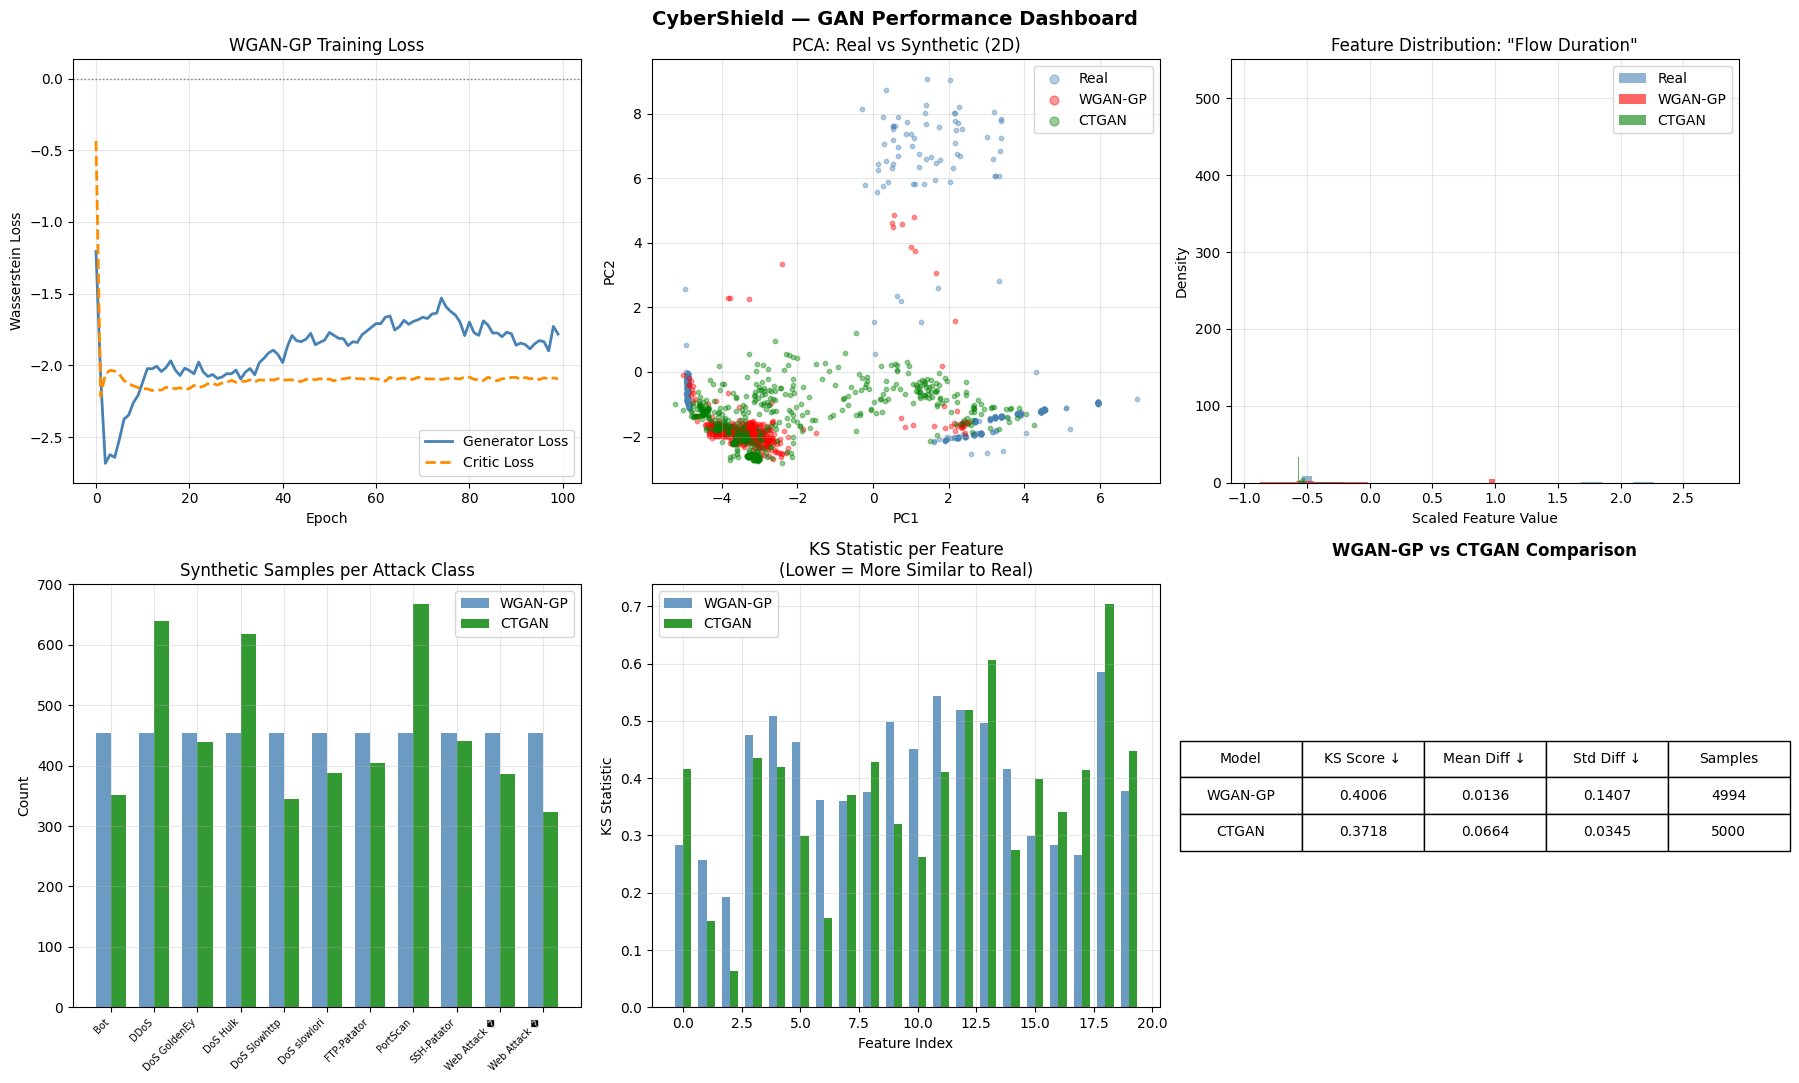

   Saved → gan_dashboard.png

✅ Step 8 Execution Completed.


In [9]:
# -------------------------------------------------------------------------
# Step 8: Visualization Dashboard
# -------------------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

print("\n📊 Generating GAN dashboard...")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('CyberShield — GAN Performance Dashboard',
             fontsize=14, fontweight='bold')

# ── Plot 1: WGAN-GP Loss Curves
axes[0, 0].plot(wgan_g_losses, label='Generator Loss',
                color='steelblue', linewidth=2)
axes[0, 0].plot(wgan_c_losses, label='Critic Loss',
                color='darkorange', linewidth=2, linestyle='--')
axes[0, 0].axhline(0, color='grey', linestyle=':', linewidth=1)
axes[0, 0].set_title('WGAN-GP Training Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Wasserstein Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# ── Plot 2: PCA — Real vs WGAN vs CTGAN
pca   = PCA(n_components=2, random_state=SEED)
n_viz = min(500, len(X_scaled), len(X_wgan_synth), len(X_ctgan_synth))

X_pca_real  = pca.fit_transform(X_scaled[:n_viz])
X_pca_wgan  = pca.transform(X_wgan_synth[:n_viz])
X_pca_ctgan = pca.transform(X_ctgan_synth[:n_viz])

axes[0, 1].scatter(X_pca_real[:, 0],  X_pca_real[:, 1],
                   alpha=0.4, s=10, color='steelblue', label='Real')
axes[0, 1].scatter(X_pca_wgan[:, 0],  X_pca_wgan[:, 1],
                   alpha=0.4, s=10, color='red',       label='WGAN-GP')
axes[0, 1].scatter(X_pca_ctgan[:, 0], X_pca_ctgan[:, 1],
                   alpha=0.4, s=10, color='green',     label='CTGAN')
axes[0, 1].set_title('PCA: Real vs Synthetic (2D)')
axes[0, 1].set_xlabel('PC1')
axes[0, 1].set_ylabel('PC2')
axes[0, 1].legend(markerscale=2)
axes[0, 1].grid(True, alpha=0.3)

# ── Plot 3: Feature Distribution (first feature)
feat_idx = 0
axes[0, 2].hist(X_scaled[:, feat_idx],      bins=40, alpha=0.6,
                color='steelblue', label='Real',    density=True)
axes[0, 2].hist(X_wgan_synth[:, feat_idx],  bins=40, alpha=0.6,
                color='red',       label='WGAN-GP', density=True)
axes[0, 2].hist(X_ctgan_synth[:, feat_idx], bins=40, alpha=0.6,
                color='green',     label='CTGAN',   density=True)
axes[0, 2].set_title(f'Feature Distribution: "{feature_cols[feat_idx][:20]}"')
axes[0, 2].set_xlabel('Scaled Feature Value')
axes[0, 2].set_ylabel('Density')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# ── Plot 4: Class Distribution — WGAN vs CTGAN
wgan_class_counts  = pd.Series(le.inverse_transform(y_wgan_synth)).value_counts()
ctgan_class_counts = pd.Series(le.inverse_transform(y_ctgan_synth)).value_counts()

x_pos  = np.arange(len(class_names))
width  = 0.35
wgan_vals  = [wgan_class_counts.get(c, 0)  for c in class_names]
ctgan_vals = [ctgan_class_counts.get(c, 0) for c in class_names]

axes[1, 0].bar(x_pos - width/2, wgan_vals,  width,
               label='WGAN-GP', color='steelblue', alpha=0.8)
axes[1, 0].bar(x_pos + width/2, ctgan_vals, width,
               label='CTGAN',   color='green',     alpha=0.8)
axes[1, 0].set_title('Synthetic Samples per Attack Class')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([c[:12] for c in class_names],
                             rotation=45, ha='right', fontsize=7)
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# ── Plot 5: KS Statistic per feature
x2  = np.arange(n_feats)
w2  = 0.35
axes[1, 1].bar(x2 - w2/2, ks_wgan_vals,  w2,
               label='WGAN-GP', color='steelblue', alpha=0.8)
axes[1, 1].bar(x2 + w2/2, ks_ctgan_vals, w2,
               label='CTGAN',   color='green',     alpha=0.8)
axes[1, 1].set_title('KS Statistic per Feature\n(Lower = More Similar to Real)')
axes[1, 1].set_xlabel('Feature Index')
axes[1, 1].set_ylabel('KS Statistic')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# ── Plot 6: Comparison Summary Table
df_cmp = pd.DataFrame({
    'Model'      : ['WGAN-GP', 'CTGAN'],
    'KS Score ↓' : [round(np.mean(ks_wgan_vals), 4),
                    round(np.mean(ks_ctgan_vals), 4)],
    'Mean Diff ↓': [round(abs(stats_wgan['Mean']  - stats_real['Mean']),  4),
                    round(abs(stats_ctgan['Mean']  - stats_real['Mean']), 4)],
    'Std Diff ↓' : [round(abs(stats_wgan['Std']   - stats_real['Std']),  4),
                    round(abs(stats_ctgan['Std']   - stats_real['Std']), 4)],
    'Samples'    : [X_wgan_synth.shape[0], X_ctgan_synth.shape[0]],
})

axes[1, 2].axis('off')
table = axes[1, 2].table(
    cellText  = df_cmp.values,
    colLabels = df_cmp.columns,
    loc       = 'center',
    cellLoc   = 'center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)
axes[1, 2].set_title('WGAN-GP vs CTGAN Comparison',
                      fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('gan_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("   Saved → gan_dashboard.png")

print(f"\n✅ Step 8 Execution Completed.")

In [10]:
# -------------------------------------------------------------------------
# Step 9: Save Models & Generated Data
# -------------------------------------------------------------------------
# Save WGAN-GP
torch.save({
    'generator_state_dict' : wgan_G.state_dict(),
    'critic_state_dict'    : wgan_C.state_dict(),
    'latent_dim'           : LATENT_DIM,
    'input_dim'            : input_dim,
    'num_classes'          : num_classes,
    'class_names'          : class_names,
    'g_losses'             : wgan_g_losses,
    'c_losses'             : wgan_c_losses,
}, 'cybershield_wgan.pth')

# Save CTGAN
ctgan.save('cybershield_ctgan.pkl')

# Save generated synthetic data
df_wgan_out = pd.DataFrame(
    scaler.inverse_transform(X_wgan_synth), columns=feature_cols
)
df_wgan_out[target_col] = le.inverse_transform(y_wgan_synth)
df_wgan_out.to_csv('wgan_synthetic_attacks.csv', index=False)
df_ctgan_synth.to_csv('ctgan_synthetic_attacks.csv', index=False)

# Save scaler and label encoder
joblib.dump(scaler, 'gan_scaler.pkl')
joblib.dump(le,     'gan_label_encoder.pkl')
df_cmp.to_csv('gan_comparison.csv', index=False)

print("\n💾 Saved:")
print("   cybershield_wgan.pth          ← WGAN-GP model weights")
print("   cybershield_ctgan.pkl         ← CTGAN model")
print("   wgan_synthetic_attacks.csv    ← WGAN-GP generated data")
print("   ctgan_synthetic_attacks.csv   ← CTGAN generated data")
print("   gan_scaler.pkl                ← feature scaler")
print("   gan_label_encoder.pkl         ← label encoder")
print("   gan_comparison.csv            ← quality comparison table")
print("   gan_dashboard.png             ← visualization dashboard")

print(f"\n{'='*60}")
print("  ✅ GAN Module Complete")
print(f"{'='*60}")
print(f"  WGAN-GP mean KS : {np.mean(ks_wgan_vals):.4f}  (lower = better)")
print(f"  CTGAN  mean KS  : {np.mean(ks_ctgan_vals):.4f}  (lower = better)")
print(f"  WGAN samples    : {X_wgan_synth.shape[0]:,}")
print(f"  CTGAN samples   : {X_ctgan_synth.shape[0]:,}")


💾 Saved:
   cybershield_wgan.pth          ← WGAN-GP model weights
   cybershield_ctgan.pkl         ← CTGAN model
   wgan_synthetic_attacks.csv    ← WGAN-GP generated data
   ctgan_synthetic_attacks.csv   ← CTGAN generated data
   gan_scaler.pkl                ← feature scaler
   gan_label_encoder.pkl         ← label encoder
   gan_comparison.csv            ← quality comparison table
   gan_dashboard.png             ← visualization dashboard

  ✅ GAN Module Complete
  WGAN-GP mean KS : 0.4006  (lower = better)
  CTGAN  mean KS  : 0.3718  (lower = better)
  WGAN samples    : 4,994
  CTGAN samples   : 5,000
